# Лабораторная работа №4. Обнаружение объектов на изображении

**Цель работы:** исследовать обнаружение объектов корреляционным методом
и согласованным фильтром на некоррелированном и коррелированном фоне.

**Вариант 27.** Размер изображения $64\times64$. Размер эталона $3\times3$.
Яркость ненулевых пикселей объекта — 128. Начальное состояние генератора — 1027.

| Сценарий | Объекты | Дисперсия фона $D_f$ | Корреляция соседей $\rho$ |
|---|---|---:|---:|
| 1 | Четыре «+» | 3000 и 5000 | 0 |
| 2 | Два «+» и два «T» | 3000 | 0,8 |

## 1. Эталоны и размещение объектов

Индекс первого эталона определяется по формуле $i=(N-1)\bmod5$, второго —
$j=(i+1)\bmod5$. В первом сценарии используется только первый тип. Во втором
оба типа присутствуют в одном кадре и обнаруживаются раздельно.

Центры выбираются воспроизводимо. Между центрами требуется не менее 10
пикселей по расстоянию Чебышёва, то есть по большему из двух смещений.
Так окна объектов не пересекаются, а соседние объекты не подавляют друг
друга при выделении пиков. Координаты записываются как (строка, столбец)
с отсчётом от нуля.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

N = 27
SEED = 1000 + N
SIZE = 64
AMPLITUDE = 128
MIN_SPACING = 10
MARGIN = 4
NMS_RADIUS = 2
MATCH_RADIUS = 1
THRESHOLD_SIGMAS = 3

rng = np.random.default_rng(SEED)
templates = {
    'X': np.array([[1, 0, 1], [0, 1, 0], [1, 0, 1]]),
    '+': np.array([[0, 1, 0], [1, 1, 1], [0, 1, 0]]),
    'T': np.array([[1, 1, 1], [0, 1, 0], [0, 1, 0]]),
    '□': np.array([[1, 1, 1], [1, 0, 1], [1, 1, 1]]),
    '⊢': np.array([[1, 0, 0], [1, 1, 1], [1, 0, 0]]),
}
names = tuple(templates)
i = (N - 1) % len(names)
first_type, second_type = names[i], names[(i + 1) % len(names)]


def chebyshev(a, b):
    return max(abs(a[0] - b[0]), abs(a[1] - b[1]))


def make_objects(types):
    image = np.zeros((SIZE, SIZE), dtype=float)
    truth = {kind: [] for kind in dict.fromkeys(types)}
    centers = []
    for kind in types:
        while True:
            row, col = map(int, rng.integers(MARGIN, SIZE - MARGIN, size=2))
            if all(chebyshev((row, col), other) >= MIN_SPACING for other in centers):
                break
        image[row-1:row+2, col-1:col+2] = AMPLITUDE * templates[kind]
        truth[kind].append((row, col))
        centers.append((row, col))
    return image, truth


objects_1, truth_1 = make_objects([first_type] * 4)
objects_2, truth_2 = make_objects([first_type, second_type] * 2)
print(f'N={N}, seed={SEED}, сценарий 1: {truth_1}, сценарий 2: {truth_2}')

N=27, seed=1027, сценарий 1: {'+': [(38, 5), (6, 35), (26, 35), (24, 4)]}, сценарий 2: {'+': [(51, 54), (36, 24)], 'T': [(20, 59), (51, 10)]}


## 2. Синтез фона и проверка его характеристик

Фон строится из независимых стандартных гауссовских отсчётов.
Для получения коррелированного поля по каждой оси применяется рекурсия
$u_k=\rho u_{k-1}+\sqrt{1-\rho^2}\,\epsilon_k$. Первый отсчёт уже имеет
единичную дисперсию, поэтому рекурсия сохраняет её начиная с границы.
Обработка по двум осям даёт ковариацию
$B_f(\Delta m,\Delta n)=D_f\rho^{|\Delta m|+|\Delta n|}$. При $\rho=0$
исходные отсчёты остаются независимыми.

Две дисперсии в первом сценарии получаются масштабированием одной и той же
реализации белого шума. Это позволяет сравнить влияние интенсивности помех
при неизменных положении объектов и пространственном рисунке шума.
Таблица проверяет эмпирические среднее, дисперсию и корреляцию соседей
по двум осям. Заданные значения относятся к случайному полю, поэтому оценки
на одном кадре могут отличаться. Сумма фона и объектов хранится в вещественном
виде без обрезки яркостей.

In [2]:
def make_background(innovations, variance, rho):
    field = innovations.copy()
    gain = np.sqrt(1 - rho**2)
    for lines in (field, field.T):
        for k in range(1, len(lines)):
            lines[k] = rho * lines[k - 1] + gain * lines[k]
    return np.sqrt(variance) * field


def field_stats(field):
    rho_row = np.corrcoef(field[:-1, :].ravel(), field[1:, :].ravel())[0, 1]
    rho_col = np.corrcoef(field[:, :-1].ravel(), field[:, 1:].ravel())[0, 1]
    return field.mean(), field.var(), rho_row, rho_col


white_innovations = rng.standard_normal((SIZE, SIZE))
white_fields = {d: make_background(white_innovations, d, 0) for d in (3000, 5000)}
correlated = make_background(rng.standard_normal((SIZE, SIZE)), 3000, .8)
observed_1 = {d: field + objects_1 for d, field in white_fields.items()}
observed_2 = correlated + objects_2

stats_lines = [
    '| Фон | Заданная дисперсия | Среднее | Дисперсия | ρ по строкам | ρ по столбцам |',
    '|---|---:|---:|---:|---:|---:|',
]
for label, d, field in [('Белый', d, b) for d, b in white_fields.items()] + [
    ('Коррелированный', 3000, correlated)
]:
    mean, var, rho_row, rho_col = field_stats(field)
    stats_lines.append(f'| {label} | {d} | {mean:.2f} | {var:.2f} | {rho_row:.3f} | {rho_col:.3f} |')
display(Markdown('\n'.join(stats_lines)))

| Фон | Заданная дисперсия | Среднее | Дисперсия | ρ по строкам | ρ по столбцам |
|---|---:|---:|---:|---:|---:|
| Белый | 3000 | 0.07 | 2917.32 | -0.005 | 0.009 |
| Белый | 5000 | 0.09 | 4862.20 | -0.005 | 0.009 |
| Коррелированный | 3000 | 6.35 | 2993.12 | 0.801 | 0.804 |

## 3. Коррелятор, согласованный фильтр и правило выбора порога

В каждом положении окна вычисляется скалярное произведение с эталоном:
$B(m,n)=\sum_{k,l}x(m+k,n+l)t(k,l)$. Это обычная взаимная корреляция.
Эталон сохраняет ориентацию, поскольку в сумме используются смещения
со знаком «плюс». При реализации через свёртку эталон пришлось бы развернуть
на $180^\circ$, что существенно для несимметричного «T».

Для коррелированного фона используется двухэтапная схема методички:
обработка наблюдаемого кадра маской $A$, затем корреляция с исходным эталоном.

$$
A=\begin{pmatrix}a_2&a_1&a_2\\a_1&1&a_1\\a_2&a_1&a_2\end{pmatrix},
\qquad a_1=-\frac{\rho}{1+\rho^2},\quad
a_2=\frac{\rho^2}{(1+\rho^2)^2}.
$$

Общий положительный множитель $a_0/D_f$ опущен. Он меняет масштаб отклика
и рассчитанного порога одинаково. Маска симметрична, поэтому её корреляция
и свёртка совпадают. В терминах спектра этот этап реализует взвешивание
обратным спектром фона, с точностью до множителя. Методичка называет его разбеливанием. Если рассматривать выход этой стадии отдельно, его спектр пропорционален обратному спектру фона и в общем случае не является плоским. Для точного разбеливания отдельного поля потребовался бы множитель $1/\sqrt{\Phi_f}$ с последующей корреляцией с эталоном, обработанным так же. При $\rho=0$ маска
превращается в единичный импульс, и остаётся обычный коррелятор.

Отклик вычисляется только там, где окно целиком помещается в изображение.
В сценарии 1 исключается рамка шириной один пиксель. В сценарии 2 для обоих
методов используется общая область с рамкой в два пикселя, которую требуют
два последовательных окна. Центр отклика сохраняет координаты исходного кадра.

Порог для каждого отклика задан одной формулой $L=3\sigma_B$. Для фонового
отклика с эффективной маской $K$ дисперсия вычисляется по модели:

$$\sigma_B^2=D_f\sum_{p,q}K_pK_q\rho^{|p_m-q_m|+|p_n-q_n|}.$$

$K$ — сам эталон для обычного коррелятора либо результирующая маска
двух окон для согласованного фильтра. При нормальном фоне вероятность
превышения $3\sigma_B$ в одной точке около 0,135%. Это ориентир до отбора
максимумов: отклики в соседних точках зависимы, а другой тип объекта тоже
может дать высокий отклик. На гистограммах порог показан вертикальной линией.
Истинные координаты используются для оценки детектора после выбора порога.

In [3]:
def correlate_valid(image, kernel):
    height, width = image.shape
    kh, kw = kernel.shape
    output = np.empty((height - kh + 1, width - kw + 1), dtype=float)
    for row in range(output.shape[0]):
        for col in range(output.shape[1]):
            window = image[row:row+kh, col:col+kw]
            output[row, col] = np.sum(window * kernel)
    return output


def whitening_mask(rho):
    a1 = -rho / (1 + rho**2)
    a2 = a1**2
    return np.array([[a2, a1, a2], [a1, 1, a1], [a2, a1, a2]])


def combined_kernel(template, mask):
    rows, cols = template.shape
    mh, mw = mask.shape
    kernel = np.zeros((rows + mh - 1, cols + mw - 1))
    for (row, col), weight in np.ndenumerate(template):
        kernel[row:row+mh, col:col+mw] += weight * mask
    return kernel


def background_sigma(kernel, variance, rho):
    row, col = np.indices(kernel.shape).reshape(2, -1)
    distance = abs(row[:, None] - row) + abs(col[:, None] - col)
    covariance = variance * rho**distance
    weights = kernel.ravel()
    return float(np.sqrt(weights @ covariance @ weights))


mask = whitening_mask(.8)
whitened = correlate_valid(observed_2, mask)
whitened_background = correlate_valid(correlated, mask)
a0 = ((1 + .8**2) / (1 - .8**2))**2
print(f'a0={a0:.5f}, a1={mask[0, 1]:.5f}, a2={mask[0, 0]:.5f}')
print(mask)
mean, var, rho_row, rho_col = field_stats(whitened_background)
print(f'После обработки фона: среднее={mean:.3f}, дисперсия={var:.2f}, '
      f'ρ по строкам={rho_row:.3f}, по столбцам={rho_col:.3f}')

a0=20.75309, a1=-0.48780, a2=0.23795
[[ 0.2379536  -0.48780488  0.2379536 ]
 [-0.48780488  1.         -0.48780488]
 [ 0.2379536  -0.48780488  0.2379536 ]]
После обработки фона: среднее=0.009, дисперсия=141.45, ρ по строкам=-0.487, по столбцам=-0.486


### Отбор пиков и проверка координат

Сначала оставляются точки со строгим превышением порога. Из них выбираются
максимумы в окне с радиусом 2 по Чебышёву. При равных откликах первыми
проверяются меньшие номера строки и столбца. Среди максимумов, расстояние
между которыми не больше 2, остаётся один пик с приоритетом по величине отклика.

Обнаружение считается правильным, если оно находится не дальше одного
пикселя по Чебышёву от истинного центра **этого типа**. Для каждого объекта
берётся не более одного обнаружения, с приоритетом по близости к центру.
Области допуска разных объектов не пересекаются из-за правила размещения.
Оставшиеся пики считаются ложными, объекты без пары — пропущенными.

In [4]:
def find_peaks(response, threshold, border):
    candidates = []
    radius = NMS_RADIUS
    rows, cols = response.shape
    for row, col in np.argwhere(response > threshold):
        window = response[max(0, row-radius):min(rows, row+radius+1),
                          max(0, col-radius):min(cols, col+radius+1)]
        score = response[row, col]
        if score == window.max():
            candidates.append((float(score), int(row + border), int(col + border)))
    peaks = []
    for _, row, col in sorted(candidates, key=lambda p: (-p[0], p[1], p[2])):
        point = (row, col)
        if all(chebyshev(point, other) > radius for other in peaks):
            peaks.append(point)
    return peaks


def evaluate(peaks, truth):
    unmatched = set(peaks)
    correct, missed = [], []
    for center in truth:
        nearby = [p for p in unmatched if chebyshev(p, center) <= MATCH_RADIUS]
        if nearby:
            closest = min(nearby, key=lambda p: (chebyshev(p, center), p))
            correct.append(closest)
            unmatched.remove(closest)
        else:
            missed.append(center)
    return correct, sorted(unmatched), missed


def run_detection(response, kernel, variance, rho, border, truth):
    sigma = background_sigma(kernel, variance, rho)
    threshold = THRESHOLD_SIGMAS * sigma
    peaks = find_peaks(response, threshold, border)
    correct, false, missed = evaluate(peaks, truth)
    assert len(correct) + len(missed) == len(truth)
    assert len(correct) + len(false) == len(peaks)
    return dict(response=response, border=border, sigma=sigma, threshold=threshold,
                peaks=peaks, correct=correct, false=false, missed=missed, truth=truth)

### Проверка реализации на небольших примерах

Проверяется ориентация несимметричного эталона, совпадение двух последовательных
проходов с объединённой маской и совпадение разбеливания при $\rho=0$
с внутренней частью изображения. Отдельный пример проверяет строгий порог,
подавление соседнего отклика и подсчёт правильных, ложных и пропущенных центров.

In [5]:
test_template = templates[second_type]
test_image = np.zeros((9, 9))
test_image[3:6, 3:6] = test_template
test_response = correlate_valid(test_image, test_template)
assert test_response[3, 3] == 5
assert correlate_valid(test_image, test_template[::-1, ::-1])[3, 3] == 3
np.testing.assert_allclose(
    correlate_valid(correlate_valid(test_image, mask), test_template),
    correlate_valid(test_image, combined_kernel(test_template, mask)), atol=1e-12,
)
np.testing.assert_array_equal(correlate_valid(test_image, whitening_mask(0)), test_image[1:-1, 1:-1])
np.testing.assert_allclose(background_sigma(test_template, 3000, 0), np.sqrt(15000))

test_map = np.zeros((9, 9))
test_map[1, 1], test_map[1, 2], test_map[6, 6], test_map[7, 2] = 9, 8, 7, 6
test_peaks = find_peaks(test_map, threshold=6, border=1)
assert test_peaks == [(2, 2), (7, 7)]
assert evaluate(test_peaks, [(2, 3), (8, 2)]) == ([(2, 2)], [(7, 7)], [(8, 2)])
print('Проверки корреляции, разбеливания, порога и сопоставления пройдены.')

Проверки корреляции, разбеливания, порога и сопоставления пройдены.


## 4. Представление результатов обнаружения

На исходных панелях показываются фон, объекты и их сумма. Для сопоставления
яркостей фона используется общий масштаб на всех кадрах. Карты отклика
выравниваются по координатам исходного изображения. Пустая рамка означает,
что в этих точках окно не вычислялось. Гистограмма включает все рассчитанные
отклики, а не только выделенные максимумы.

На наблюдаемом кадре отмечаются истинные центры и результат сопоставления.
Зелёная окружность обозначает правильное обнаружение, красный крест — ложное,
жёлтый ромб — пропуск.

In [6]:
def show_image(ax, image, title, *, cmap='gray', vmin=None, vmax=None):
    im = ax.imshow(image, cmap=cmap, origin='upper', interpolation='nearest',
                   vmin=vmin, vmax=vmax)
    ax.set_title(title, fontsize=10)
    ax.set(xlabel='Столбец', ylabel='Строка')
    return im


def show_inputs(figure, axes, background, objects, observed):
    for ax, image, label in zip(axes, (background, objects, observed),
                               ('Фон', 'Изображение объектов', 'Наблюдаемое изображение')):
        bounds = (0, AMPLITUDE) if label == 'Изображение объектов' else (-220, 280)
        im = show_image(ax, image, label, vmin=bounds[0], vmax=bounds[1])
        figure.colorbar(im, ax=ax, shrink=.75)


def show_detection(figure, axes, observed, result):
    response = result['response']
    border = result['border']
    full = np.pad(response, border, constant_values=np.nan)
    im = show_image(axes[0], full, 'Карта корреляционных откликов', cmap='viridis')
    figure.colorbar(im, ax=axes[0], shrink=.75)

    hist_ax = axes[1]
    hist_ax.hist(response.ravel(), bins=45, color='#427aa1')
    threshold = result['threshold']
    hist_ax.axvline(threshold, color='#a7243d', linestyle='--', label=f'L = {threshold:.1f}')
    hist_ax.set(title='Распределение откликов', xlabel='Отклик', ylabel='Число окон')
    hist_ax.legend(loc='upper right')

    ax = axes[2]
    show_image(ax, observed, 'Разметка центров', vmin=-220, vmax=280)
    for key, marker, color, label in [
        ('truth', '+', 'white', 'Истинный центр'),
        ('correct', 'o', '#77ef86', 'Правильное'),
        ('false', 'x', '#ff6464', 'Ложное'),
        ('missed', 'D', '#ffdc65', 'Пропуск'),
    ]:
        points = result[key]
        if points:
            rows, cols = np.asarray(points).T
            if marker in ('o', 'D'):
                ax.scatter(cols, rows, marker=marker, facecolors='none',
                           edgecolors=color, linewidths=1.5, s=63, label=label)
            else:
                ax.scatter(cols, rows, marker=marker, color=color, s=38, label=label)
    ax.legend(loc='upper center', bbox_to_anchor=(.5, -.19), ncol=2, fontsize=8)

### 4.1. Сценарий 1. Четыре объекта «+» на белом фоне

Один и тот же эталон применяется к двум кадрам с одинаковыми объектами.
При увеличении дисперсии меняются разброс откликов на фоне и порог;
фиксированная яркость объектов позволяет проследить, как это сказывается на
числе правильных, ложных и пропущенных обнаружений.

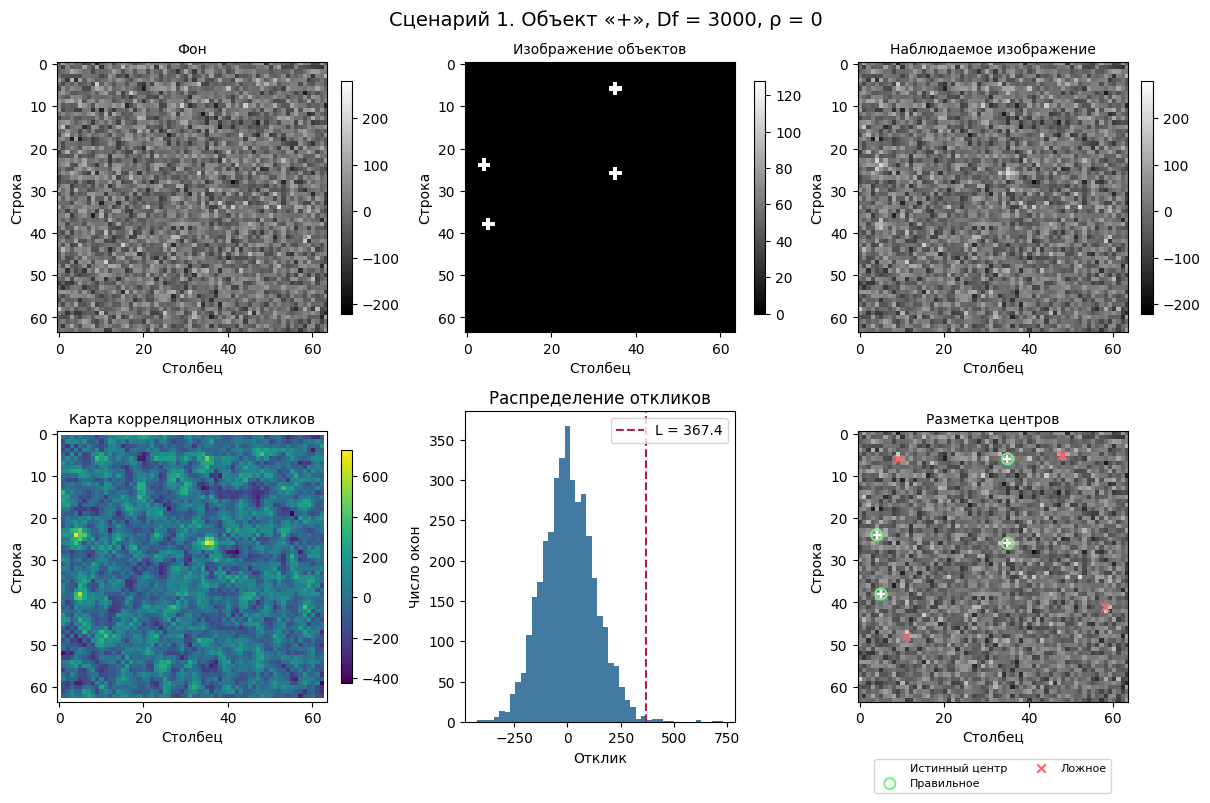

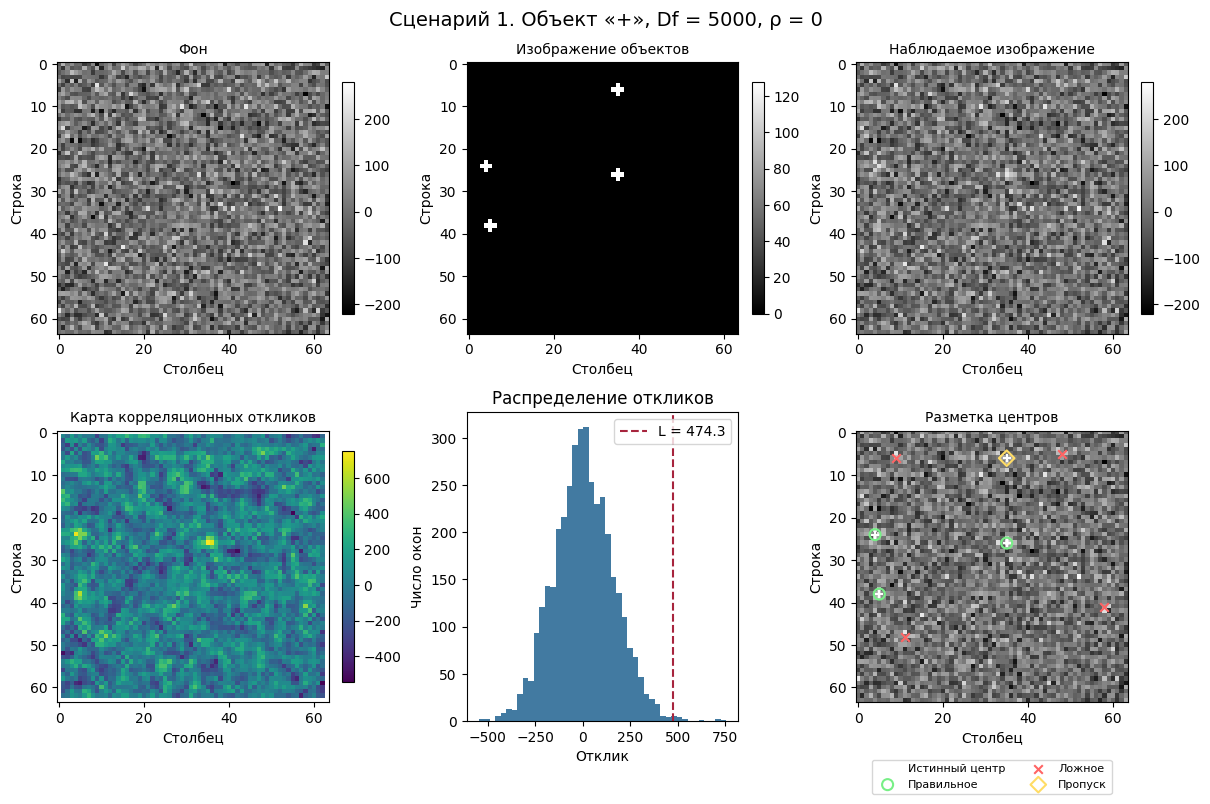

In [7]:
results_1 = {}
for variance, observed in observed_1.items():
    template = templates[first_type]
    response = correlate_valid(observed, template)
    result = run_detection(response, template, variance, 0, 1, truth_1[first_type])
    results_1[variance] = result

    fig, ax = plt.subplots(2, 3, figsize=(12, 8), layout='constrained')
    fig.suptitle(f'Сценарий 1. Объект «{first_type}», Df = {variance}, ρ = 0', fontsize=14)
    show_inputs(fig, ax[0], white_fields[variance], objects_1, observed)
    show_detection(fig, ax[1], observed, result)
    plt.show()

### 4.2. Сценарий 2. Объекты «+» и «T» на коррелированном фоне

Все четыре обработки используют один наблюдаемый кадр. Ниже показаны общие
входные изображения и промежуточный кадр после обработки разбеливающей маской.
На изображении объектов подписаны типы. После обработки маской исключена
внешняя рамка из одного пикселя, что видно на последней панели.

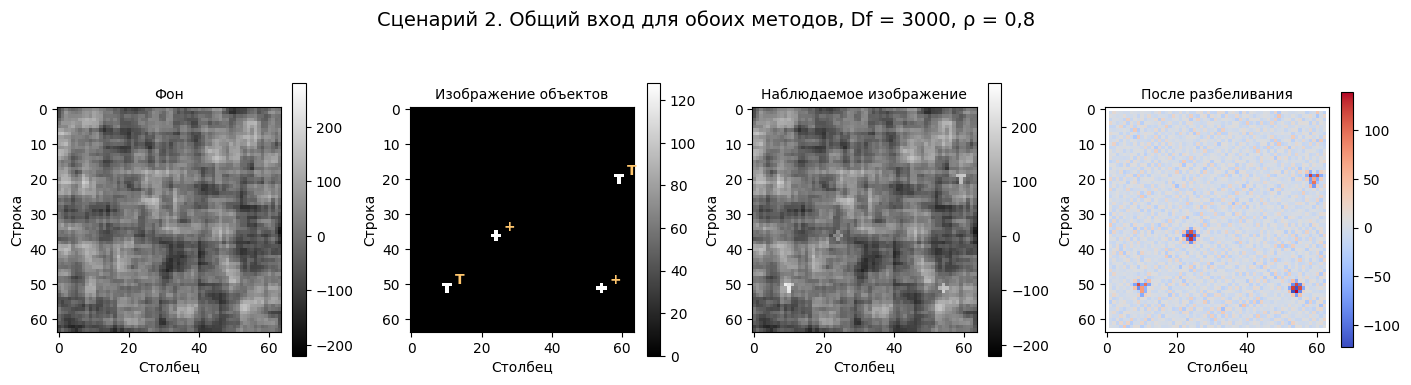

In [8]:
fig, ax = plt.subplots(1, 4, figsize=(14, 4), layout='constrained')
fig.suptitle('Сценарий 2. Общий вход для обоих методов, Df = 3000, ρ = 0,8', fontsize=14)
show_inputs(fig, ax[:3], correlated, objects_2, observed_2)
for kind, points in truth_2.items():
    for row, col in points:
        ax[1].annotate(kind, (col, row), xytext=(6, 3), textcoords='offset points',
                       color='#ffc66d', weight='bold')
im = show_image(ax[3], np.pad(whitened, 1, constant_values=np.nan),
                'После разбеливания', cmap='coolwarm')
fig.colorbar(im, ax=ax[3], shrink=.7)
plt.show()

Для каждого типа отдельно сравниваются отклики обычной корреляции
и согласованного фильтра. Сопоставление выполняется только с разметкой
целевого типа. Поэтому сильный отклик на другой тип учитывается как
ложное обнаружение для данного эталона.

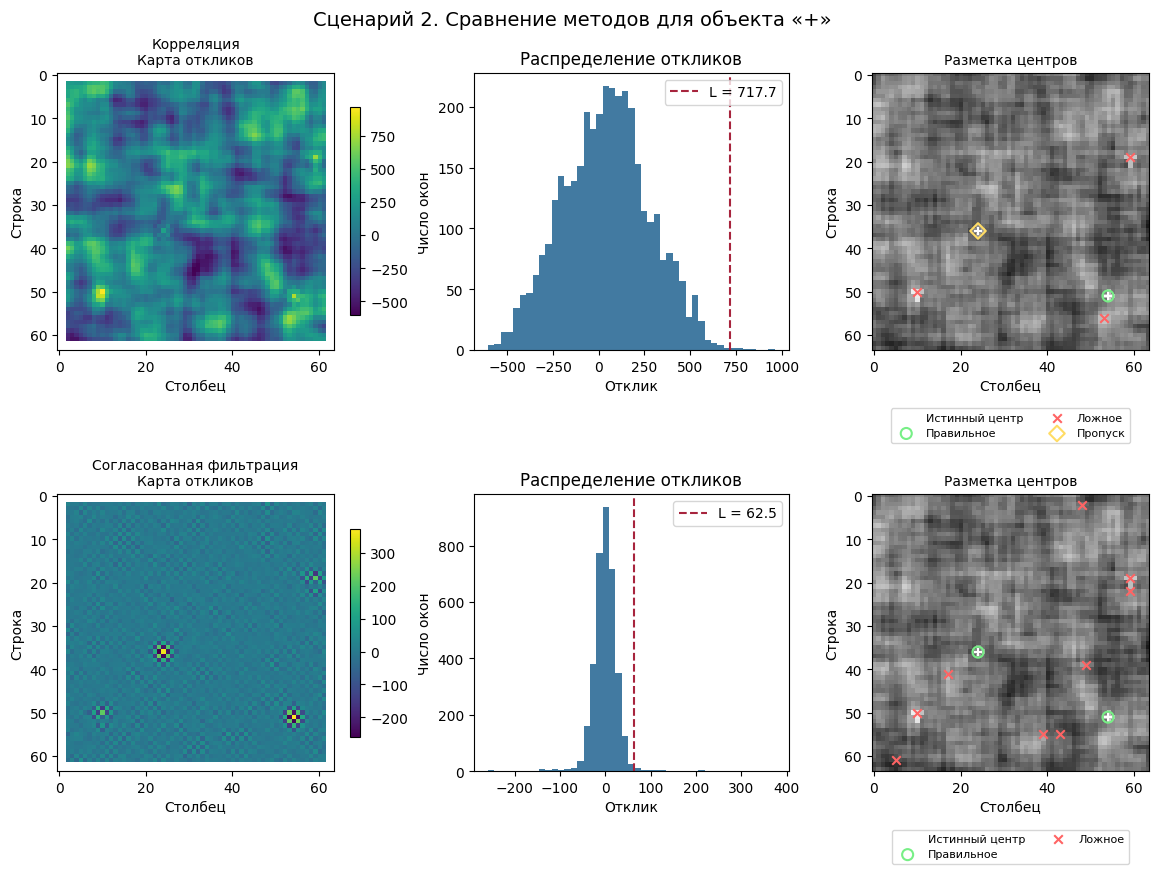

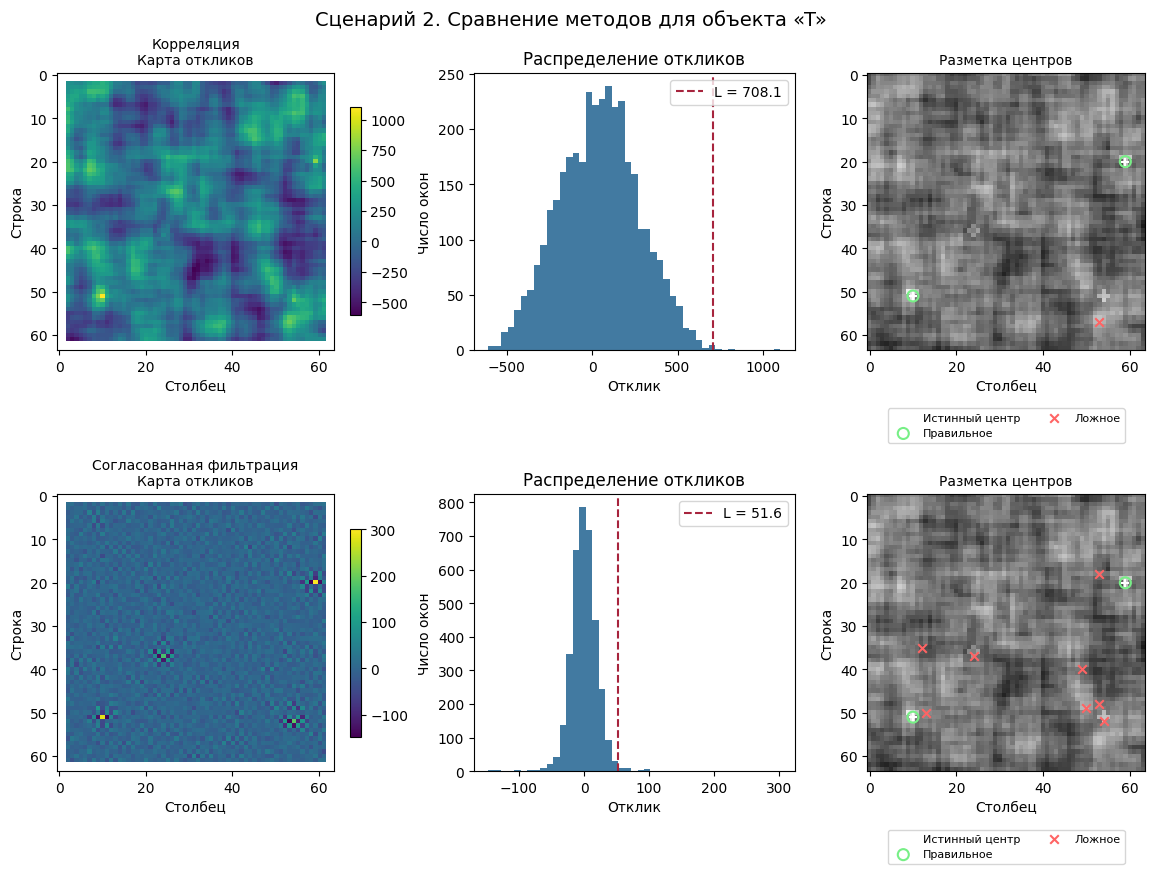

In [9]:
results_2 = {}
for kind, truth in truth_2.items():
    template = templates[kind]
    raw = correlate_valid(observed_2[1:-1, 1:-1], template)
    matched = correlate_valid(whitened, template)
    assert raw.shape == matched.shape == (SIZE-4, SIZE-4)
    np.testing.assert_allclose(
        matched, correlate_valid(observed_2, combined_kernel(template, mask)), atol=1e-10,
    )

    fig, ax = plt.subplots(2, 3, figsize=(12, 8.7), layout='constrained')
    fig.suptitle(f'Сценарий 2. Сравнение методов для объекта «{kind}»', fontsize=14)
    for axes, (method, response, kernel) in zip(ax, [
        ('Корреляция', raw, template),
        ('Согласованная фильтрация', matched, combined_kernel(template, mask)),
    ]):
        result = run_detection(response, kernel, 3000, .8, 2, truth)
        results_2[kind, method] = result
        show_detection(fig, axes, observed_2, result)
        axes[0].set_title(f'{method}\nКарта откликов', fontsize=10)
    plt.show()

## 5. Результаты

Таблицы показывают пороги в единицах отклика и числа обнаружений. Для проверки
приведены координаты всех правильных, ложных и пропущенных объектов. Для пропуска
указывается истинный центр, для правильного и ложного обнаружения — координата
выделенного пика.

In [10]:
header = '| Тип | Условие / метод | σ отклика | Порог L | Правильные | Ложные | Пропущенные |'
divider = '|:--:|---|---:|---:|---:|---:|---:|'


def result_row(kind, condition, result):
    return (f'| {kind} | {condition} | {result["sigma"]:.2f} | {result["threshold"]:.2f} | '
            f'{len(result["correct"])} | {len(result["false"])} | {len(result["missed"])} |')


rows_1 = [result_row(first_type, f'Df = {d}', result) for d, result in results_1.items()]
rows_2 = [result_row(kind, method, result) for (kind, method), result in results_2.items()]
for title, rows in [('Сценарий 1', rows_1), ('Сценарий 2', rows_2)]:
    display(Markdown('\n'.join([f'**{title}**', '', header, divider, *rows])))

for label, result in [(f'Df = {d}', r) for d, r in results_1.items()] + [
    (f'{kind}, {method}', r) for (kind, method), r in results_2.items()
]:
    print(f'{label}: правильно {result["correct"]}, ложные {result["false"]}, '
          f'пропущены {result["missed"]}')

**Сценарий 1**

| Тип | Условие / метод | σ отклика | Порог L | Правильные | Ложные | Пропущенные |
|:--:|---|---:|---:|---:|---:|---:|
| + | Df = 3000 | 122.47 | 367.42 | 4 | 4 | 0 |
| + | Df = 5000 | 158.11 | 474.34 | 3 | 4 | 1 |

**Сценарий 2**

| Тип | Условие / метод | σ отклика | Порог L | Правильные | Ложные | Пропущенные |
|:--:|---|---:|---:|---:|---:|---:|
| + | Корреляция | 239.25 | 717.75 | 1 | 3 | 1 |
| + | Согласованная фильтрация | 20.83 | 62.49 | 2 | 9 | 0 |
| T | Корреляция | 236.02 | 708.05 | 2 | 1 | 0 |
| T | Согласованная фильтрация | 17.21 | 51.64 | 2 | 8 | 0 |

Df = 3000: правильно [(38, 5), (6, 35), (26, 35), (24, 4)], ложные [(5, 48), (6, 9), (41, 58), (48, 11)], пропущены []
Df = 5000: правильно [(38, 5), (26, 35), (24, 4)], ложные [(5, 48), (6, 9), (41, 58), (48, 11)], пропущены [(6, 35)]
+, Корреляция: правильно [(51, 54)], ложные [(19, 59), (50, 10), (56, 53)], пропущены [(36, 24)]
+, Согласованная фильтрация: правильно [(51, 54), (36, 24)], ложные [(2, 48), (19, 59), (22, 59), (39, 49), (41, 17), (50, 10), (55, 39), (55, 43), (61, 5)], пропущены []
T, Корреляция: правильно [(20, 59), (51, 10)], ложные [(57, 53)], пропущены []
T, Согласованная фильтрация: правильно [(20, 59), (51, 10)], ложные [(18, 53), (35, 12), (37, 24), (40, 49), (48, 53), (49, 50), (50, 13), (52, 54)], пропущены []


### Проверка причин ошибок

Для пропущенных объектов сравнивается максимальный отклик в пределах
допуска в один пиксель с порогом. Дополнительно сопоставляются отклики
в центрах объектов без шума в единицах $\sigma_B$: это позволяет сравнить
разные масштабы фильтров.

Поскольку фон и изображение объектов сгенерированы раздельно, можно проверить
вклад фона в ложные обнаружения. Для каждого ложного пика проверяется,
превышает ли порог отклик **в той же точке** на одном фоне. Также отмечаются
пики в пределах одного пикселя от центра другого типа. Это две независимые
проверки по координатам. Результаты служат для анализа ошибок после детекции.

In [11]:
for condition, result in [
    *[(f'Df = {d}', r) for d, r in results_1.items()],
    *[(f'{kind}, {method}', r) for (kind, method), r in results_2.items()],
]:
    border = result['border']
    for row, col in result['missed']:
        r, c = row - border, col - border
        local = result['response'][r-MATCH_RADIUS:r+MATCH_RADIUS+1,
                                   c-MATCH_RADIUS:c+MATCH_RADIUS+1]
        print(f'{condition}, пропуск {(row, col)}: максимум рядом = {local.max():.2f}, '
              f'порог = {result["threshold"]:.2f}')

print('\nОтклики на объекты без шума и анализ ложных пиков:')
for (kind, method), result in results_2.items():
    template = templates[kind]
    kernel = template if method == 'Корреляция' else combined_kernel(template, mask)
    border = result['border']
    trim = border - kernel.shape[0] // 2
    inner = slice(trim, SIZE - trim)
    background_response = correlate_valid(correlated[inner, inner], kernel)
    clean_response = correlate_valid(objects_2[inner, inner], kernel)
    np.testing.assert_allclose(result['response'], background_response + clean_response, atol=1e-10)
    row, col = result['truth'][0]
    clean_score = clean_response[row-border, col-border] / result['sigma']
    background_false = sum(background_response[r-border, c-border] > result['threshold']
                           for r, c in result['false'])
    other_truth = [p for other, points in truth_2.items() if other != kind for p in points]
    cross_false = sum(any(chebyshev(p, center) <= MATCH_RADIUS for center in other_truth)
                      for p in result['false'])
    print(f'{kind}, {method}: чистый отклик в центре = {clean_score:.2f}σ, '
          f'фон выше порога в {background_false} из {len(result["false"])} ложных пиков, '
          f'пиков у центров другого типа: {cross_false}')

Df = 5000, пропуск (6, 35): максимум рядом = 442.05, порог = 474.34
+, Корреляция, пропуск (36, 24): максимум рядом = 291.80, порог = 717.75

Отклики на объекты без шума и анализ ложных пиков:
+, Корреляция: чистый отклик в центре = 2.68σ, фон выше порога в 1 из 3 ложных пиков, пиков у центров другого типа: 2
+, Согласованная фильтрация: чистый отклик в центре = 18.44σ, фон выше порога в 6 из 9 ложных пиков, пиков у центров другого типа: 2
T, Корреляция: чистый отклик в центре = 2.71σ, фон выше порога в 1 из 1 ложных пиков, пиков у центров другого типа: 0
T, Согласованная фильтрация: чистый отклик в центре = 15.24σ, фон выше порога в 4 из 8 ложных пиков, пиков у центров другого типа: 2


## 6. Выводы

1. **Некоррелированный фон.** При увеличении $D_f$ с 3000 до 5000 порог
   вырос с 367,42 до 474,34. Число правильных обнаружений снизилось с
   четырёх до трёх, а ложных осталось четыре. Для пропущенного объекта
   $(6,35)$ даже максимальный отклик в окрестности (442,05) оказался ниже
   нового порога. При одинаковой яркости объектов рост дисперсии ухудшил
   их различимость на фоне.
2. **Коррелированный фон.** Для «+» согласованная фильтрация устранила
   один пропуск, но увеличила число ложных обнаружений с 3 до 9. Для «T»
   оба метода нашли оба объекта, а число ложных обнаружений выросло с 1
   до 8. Отклик на объект без шума относительно фонового СКО вырос с
   $2{,}68\sigma_B$ до $18{,}44\sigma_B$ для «+» и с
   $2{,}71\sigma_B$ до $15{,}24\sigma_B$ для «T». Этот выигрыш
   характеризует отклик в центре объекта. Качество детекции всего кадра
   зависит также от порога, более слабых максимумов и соседних объектов.
3. **Причины ложных обнаружений и роль эталона.** Для согласованного
   фильтра фон сам по себе превышал порог в 6 из 9 ложных пиков «+» и в
   4 из 8 ложных пиков «T». В каждом из этих двух опытов по два ложных
   пика лежали рядом с центрами объектов другого типа. У «+» и «T»
   совпадают три из пяти ненулевых позиций при совмещённых центрах.
   Из-за такого частичного совпадения и откликов при сдвиге один объект
   может дать пик для другого эталона.
4. **Действие маски.** Эмпирическая корреляция соседей исходного фона
   составляла около $0{,}80$ по обеим осям. После первого этапа она стала
   около $-0{,}49$. Это согласуется с действием маски обратной ковариации:
   она подавляет плавную составляющую фона, а её отдельный выход сохраняет
   корреляцию со знаком минус. При пороге $3\sigma_B$ на исследованном
   кадре согласованный фильтр дал выигрыш по пропускам «+», а обычная
   корреляция — по числу ложных обнаружений для обоих типов. Сравнение
   относится к данной реализации фона и выбранному правилу порога.